# Replot the saved parallel NMF experiment

**Run All loads the saved data and reproduces the figures without running any solver.**
The default snapshot contains all **20 seeds and 12 methods (240 histories)** from
`parallel_results/20261105_051152_877484/`. Keep that folder, including its JSON
metadata, with this notebook. Imports work from the repository root or `MF/`.
Required packages are NumPy, pandas, Matplotlib and Jupyter; no GALAHAD or joblib
worker is needed for this reader. The original experiment and exports are preserved.

### Relationship to the revision

Checked against the local `Lazy_Hessians_Neurips-revisedv_0.pdf`, whose PDF creation
date is 2026-11-07. The PDF drawing streams for the five single-seed MF graphics
match the saved exports exactly. All use **seed 107**. The revision's all-method
mean graphic matches `parallel_results/20261105_041839_123202/mean_gradient_GN_all.pdf`;
its raw histories are the same as the default snapshot. Figures 7 and 9 reuse
that same mean graphic. The public reference is
[arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1), Section 5.2 / Appendix E.2,
Algorithm 1 and subproblem (2). The local revision numbers the MF objective (27);
the public v1 numbers it (28). Public v1 predates these revised experiments.
The local PDF is optional and remains ignored by Git.

| Revision figure | Source export | Recreated here |
|---|---|---|
| 3: weighted nonnegativity penalty | `figure3_penalty.pdf` | `figure3_penalty` |
| 4: gradient norm, seed 107 | `representative_gradient.pdf` | `representative_gradient` |
| 7 and 9: mean gradient, all 12 methods and 20 seeds | `mean_gradient_GN_all.pdf` in the earlier export above | `mean_gradient_GN_all` |
| 8: objective residual, seed 107 | `representative_objective.pdf` | `representative_objective` |
| 10: PALM gradient comparison | `figure8_gradient.pdf` (old numbering) | `palm_gradient` |
| 10: PALM penalty comparison | `figure8_penalty.pdf` (old numbering) | `palm_penalty` |

The additional representative penalty and three eight-method mean plots reproduce
the remaining default export graphics. Thus this notebook renders **10 distinct
figures**, covering the nine saved exports plus the revision's all-method mean.

The recorded problem is `(m,n,r)=(200,100,12)`, noise 0.2, ridge weight 2,
penalty weight 200 and Gaussian initialization with standard deviation 1.
**Known manuscript discrepancy:** Appendix E.2 says initial shift Lambda_0 = 1,
but the recorded LeAP/GLAd method options use `H_0=10`. These plots retain the
actual saved run. No solver, Hessian reuse, regularization, acceptance test,
subproblem tolerance, stopping rule, seed or initialization is changed here.
The linear and cubic subproblems were solved inexactly (MINRES and GLRT).
See `../THIRD_PARTY.txt` for attribution. Draft margin comments are not treated
as adopted changes.

### Choosing a seed

1. Run the load and all-seed comparison cells.
2. In **Choose seeds and plot settings**, change `PALM_SEED` to a recorded seed
   (for example `146`), then rerun that cell and **PALM comparison**.
3. Set `SELECTED_SEED` to change the other single-seed figures too. `None` restores
   the saved seed 107. The all-seed means always retain all 20 seeds.
4. Run **Export the displayed figures** with `SAVE_FIGURES=True` to save a new
   timestamped folder, including the actual seed choices and comparison table.

A seed chosen after comparing LeAP and GLAd is an **exploratory example**, not
the automatically selected representative seed. The table retains all seeds and
the all-seed plots remain available for the overall comparison. Seed 146 gives
similar first-crossing time and iteration count at gradient norm 1e-6; inspect
the full trajectories and other targets before choosing a figure. On seed 146,
LeAP still attains a much smaller final penalty. Seed **33** is another useful
comparison: at gradient norm 1e-6, LeAP takes 40.43 s and GLAd takes 36.73 s,
with final penalties about 0.00144 and 0.00164. The all-seed endpoint details
show these tradeoffs rather than ranking by runtime alone.

In [1]:
import sys
from pathlib import Path
from datetime import datetime
from copy import deepcopy
from io import BytesIO
import gc
import hashlib
import json
import platform

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "experiment_results.py").exists():
    MF_DIR = MF_DIR / "MF"
MF_DIR = MF_DIR.resolve()
sys.path.insert(0, str(MF_DIR))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image
from experiment_results import load_experiment_snapshot
from utils_new import plot_figures, plot_penalty_iterations, prepare_mean_histories

%matplotlib inline

## Load the saved run

Only trusted local experiment snapshots should be loaded. This reads the
histories and plot settings; it does not reconstruct or train the factors.
The snapshot stores histories, not solver states for continuation.

In [2]:
RESULTS_DIRECTORY = "parallel_results/20261105_051152_877484"
source_dir = Path(RESULTS_DIRECTORY)
if not source_dir.is_absolute():
    source_dir = MF_DIR / source_dir
source_dir = source_dir.resolve()
source_file = source_dir / "results.pkl.gz"
if not source_file.exists():
    raise FileNotFoundError(f"Keep the local saved run with this notebook: {source_file}")

state = load_experiment_snapshot(source_file)
histories = state["all_seeds_histories"]
statuses = state["all_seeds_statuses"]
seeds = list(state["experiment_seeds"])
configuration = state["experiment_config"]
recorded_metadata = state["run_metadata"]
methods = [name for name in state["methods_to_run"]
           if all(name in histories[seed] for seed in seeds)]
incomplete = set().union(*(set(histories[seed]) for seed in seeds)) - set(methods)
if incomplete:
    raise ValueError(f"Incomplete method histories: {sorted(incomplete)}")
for seed in seeds:
    for method in methods:
        h = histories[seed][method]
        if len({len(h[k]) for k in ("func", "grad_norm", "penalty", "time")}) != 1:
            raise ValueError(f"Mismatched history lengths: {seed}, {method}")

metadata_names = ["representative_run", "arithmetic_mean", "figure8_gradient",
                  "figure3_penalty", "figure8_penalty"]
saved = {name: json.loads((source_dir / f"{name}.json").read_text(encoding="utf-8"))
         for name in metadata_names}
with source_file.open("rb") as source_stream:
    source_sha256 = hashlib.file_digest(source_stream, "sha256").hexdigest()
figures, figure_records = {}, {}
print(f"Loaded {len(seeds)} seeds, {len(methods)} methods, {sum(len(histories[s]) for s in seeds)} histories.")
print("Source:", source_file)
print("Available seeds:", seeds)
display(pd.DataFrame([
    dict(method=name, **{k: v for k, v in recorded_metadata["methods"][name]["options"].items()
                        if k in ("max_iter", "n_iters", "H_0", "grad_tol", "tol", "lss_tol",
                                 "use_gauss_newton", "subproblem_tol")})
    for name in methods
]))

Loaded 20 seeds, 12 methods, 240 histories.
Source: C:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\MF\parallel_results\20261105_051152_877484\results.pkl.gz
Available seeds: [549, 498, 483, 33, 528, 989, 465, 344, 150, 861, 107, 424, 998, 235, 992, 229, 725, 911, 418, 146]


,method,max_iter,grad_tol,tol,n_iters,H_0,lss_tol,use_gauss_newton,subproblem_tol
0,Gradient Method,320000.0,1.000000e-08,NaN,NaN,NaN,NaN,NaN,NaN
1,PALM,150000.0,NaN,1.000000e-08,NaN,NaN,NaN,NaN,NaN
2,LeAP-SSN,NaN,1.000000e-08,NaN,4000.0,10.0,1.000000e-07,False,NaN
3,"GLAd-SSN, p=0.2",NaN,1.000000e-08,NaN,4000.0,10.0,1.000000e-07,False,NaN
4,"GLAd-SSN, p=0.4",NaN,1.000000e-08,NaN,4000.0,10.0,1.000000e-07,False,NaN
5,"GLAd-SSN, p=0.5",NaN,1.000000e-08,NaN,4000.0,10.0,1.000000e-07,False,NaN
6,"GLAd-SSN, p=0.6",NaN,1.000000e-08,NaN,4000.0,10.0,1.000000e-07,False,NaN
7,"GLAd-SSN, p=0.8",NaN,1.000000e-08,NaN,4000.0,10.0,1.000000e-07,False,NaN
8,Cubic Newton,NaN,1.000000e-08,NaN,4000.0,10.0,NaN,NaN,1.000000e-07
9,LeAP-SSN (GN),NaN,1.000000e-08,NaN,4000.0,10.0,1.000000e-07,True,NaN


## Compare LeAP and GLAd across every seed

For each method, take the **first recorded** index where its gradient norm is at
most `COMPARISON_TARGET`, and read the cumulative runtime at that same index.
There is no interpolation. A missing crossing remains missing; it is not replaced
by the final time. A first crossing may be transient and is not a stopping claim.

The ratios are **GLAd / LeAP**: 1 means equal, below 1 means GLAd reached the
target sooner, and above 1 means LeAP reached it sooner. Rows are ordered by
`abs(log(time ratio))`, with missing crossings last. The `close` column requires
both the time and iteration ratios to lie in `[1/CLOSE_FACTOR, CLOSE_FACTOR]`.
This is an exploration aid and never changes the selected seed automatically.
Runtimes are the recorded parallel-worker timings, including shared CPU load.

Adjust the target (for example 1e-4, 1e-6, 1e-8) and rerun this cell to check
sensitivity. Final gradients, penalties, objective values and exit statuses
are also retained below; similar gradient timing need not imply similar
constraint violation or the same stationary point.

In [3]:
COMPARISON_TARGET = 1e-6
COMPARE_GLAD = "GLAd-SSN, p=0.5"
CLOSE_FACTOR = 1.25

def first_crossing(history, target):
    hits = np.flatnonzero(np.asarray(history["grad_norm"]) <= target)
    return ((int(hits[0]), float(history["time"][hits[0]])) if hits.size else (np.nan, np.nan))

def compare_seeds(target, glad_method, close_factor):
    if not np.isfinite(target) or target <= 0:
        raise ValueError("The comparison target must be positive and finite.")
    if not np.isfinite(close_factor) or close_factor < 1:
        raise ValueError("CLOSE_FACTOR must be finite and at least 1.")
    if glad_method not in methods or "LeAP-SSN" not in methods:
        raise ValueError("Both comparison methods must be available for all seeds.")
    rows = []
    for seed in seeds:
        row = dict(seed=seed)
        for short, name in [("LeAP", "LeAP-SSN"), ("GLAd", glad_method)]:
            h = histories[seed][name]
            iteration, seconds = first_crossing(h, target)
            row.update({f"{short} iterations": iteration, f"{short} seconds": seconds,
                        f"{short} final gradient": float(h["grad_norm"][-1]),
                        f"{short} final penalty": float(h["penalty"][-1]),
                        f"{short} final objective": float(h["func"][-1]),
                        f"{short} exit": statuses[seed][name]})
        for unit in ("seconds", "iterations"):
            a, b = row[f"LeAP {unit}"], row[f"GLAd {unit}"]
            row[f"GLAd/LeAP {unit}"] = b / a if np.isfinite(a) and a > 0 and np.isfinite(b) else np.nan
        ratios = [row[f"GLAd/LeAP {unit}"] for unit in ("seconds", "iterations")]
        row["both reached"] = all(np.isfinite(row[f"{name} iterations"]) for name in ("LeAP", "GLAd"))
        row["close"] = all(np.isfinite(r) and 1 / close_factor <= r <= close_factor for r in ratios)
        ratio = row["GLAd/LeAP seconds"]
        row["distance from equal time"] = abs(np.log(ratio)) if np.isfinite(ratio) and ratio > 0 else np.inf
        rows.append(row)
    return pd.DataFrame(rows).sort_values(["distance from equal time", "seed"], kind="stable").reset_index(drop=True)

seed_comparison = compare_seeds(COMPARISON_TARGET, COMPARE_GLAD, CLOSE_FACTOR)
comparison_record = dict(target=COMPARISON_TARGET, glad_method=COMPARE_GLAD, leap_method="LeAP-SSN",
                         close_factor=CLOSE_FACTOR, ratio="GLAd / LeAP", selection="manual; no automatic selection")
print(f"First gradient crossing at {COMPARISON_TARGET:g}; comparison: {COMPARE_GLAD} versus LeAP-SSN.")
display(seed_comparison[["seed", "LeAP iterations", "GLAd iterations", "GLAd/LeAP iterations",
                         "LeAP seconds", "GLAd seconds", "GLAd/LeAP seconds", "both reached", "close"]]
        .style.format(precision=3, na_rep="not reached"))
details = seed_comparison[["seed", "LeAP final gradient", "GLAd final gradient",
                           "LeAP final penalty", "GLAd final penalty",
                           "LeAP final objective", "GLAd final objective", "LeAP exit", "GLAd exit"]]
display(HTML("<details><summary>Final gradients, penalties, objectives and exits for all seeds</summary>" +
             details.to_html(index=False, float_format=lambda x: f"{x:.3e}") + "</details>"))

First gradient crossing at 1e-06; comparison: GLAd-SSN, p=0.5 versus LeAP-SSN.


,seed,LeAP iterations,GLAd iterations,GLAd/LeAP iterations,LeAP seconds,GLAd seconds,GLAd/LeAP seconds,both reached,close
0,146,1706,1574,0.923,85.379,81.279,0.952,True,True
1,498,705,929,1.318,39.732,42.484,1.069,True,False
2,33,715,848,1.186,40.433,36.728,0.908,True,True
3,465,1160,1077,0.928,65.177,57.878,0.888,True,True
4,528,1388,1836,1.323,81.979,94.203,1.149,True,False
5,235,1329,1704,1.282,85.641,101.162,1.181,True,False
6,549,1910,2870,1.503,110.932,153.671,1.385,True,False
7,725,1981,2526,1.275,102.726,146.406,1.425,True,False
8,992,2121,3060,1.443,117.523,174.813,1.487,True,False
9,418,1622,2303,1.420,81.856,123.388,1.507,True,False


seed,LeAP final gradient,GLAd final gradient,LeAP final penalty,GLAd final penalty,LeAP final objective,GLAd final objective,LeAP exit,GLAd exit
146,8.259e-09,1.373e-08,3.740e-06,4.991e-04,1.417e+03,1.417e+03,"success, 1878 iters","numerical_stagnation, 1585 iters"
498,2.197e-09,5.846e-09,1.420e-03,6.439e-03,1.421e+03,1.421e+03,"success, 708 iters","success, 931 iters"
33,3.660e-09,3.773e-08,1.442e-03,1.639e-03,1.447e+03,1.447e+03,"success, 718 iters","numerical_stagnation, 851 iters"
465,4.877e-09,1.103e-08,7.416e-05,9.974e-04,1.423e+03,1.423e+03,"success, 1165 iters","numerical_stagnation, 1080 iters"
528,5.273e-09,9.153e-09,9.533e-04,5.708e-04,1.448e+03,1.448e+03,"success, 1391 iters","success, 1839 iters"
235,2.396e-08,2.069e-08,3.444e-06,2.167e-06,1.463e+03,1.463e+03,"numerical_stagnation, 1477 iters","numerical_stagnation, 1756 iters"
549,6.445e-09,1.617e-09,2.031e-03,2.031e-03,1.449e+03,1.449e+03,"success, 1912 iters","success, 2873 iters"
725,3.085e-08,1.526e-08,6.084e-14,1.082e-03,1.451e+03,1.451e+03,"numerical_stagnation, 1993 iters","numerical_stagnation, 2532 iters"
992,4.169e-09,2.964e-08,1.172e-03,3.807e-04,1.447e+03,1.447e+03,"success, 2124 iters","numerical_stagnation, 3062 iters"
418,9.188e-09,6.796e-07,1.298e-05,4.010e-11,1.452e+03,1.452e+03,"success, 1636 iters","numerical_stagnation, 2311 iters"


## Choose seeds and plot settings

`SELECTED_SEED=None` and `PALM_SEED=None` reproduce the saved seed 107.
Set only `PALM_SEED=146` to change both PALM panels while keeping Figures 3, 4
and 8 at 107. Set `SELECTED_SEED` to change the other single-seed figures;
PALM follows that choice unless `PALM_SEED` is set separately.

Rerun this cell after editing it, then the affected plotting cell(s). No reload
or optimization is needed. Each figure has its own method list and axis limits.
`None` for an axis limit shows the full plotted range. The mean plots always
retain every recorded seed, including runs that ended by stagnation or budget.
The objective reference is the best observed value for the selected comparison,
not a certified optimum. Means use the existing aggregation and cutoff rules.

The options are reset from the saved metadata whenever this cell is rerun;
put customizations at the end of this cell so they are applied consistently.

In [4]:
SELECTED_SEED = None  # None = saved seed 107; changes the three representative plots and Figure 3.
PALM_SEED = None      # Example: 146. Overrides the seed for BOTH PALM plots only.
LINE_WIDTH = 1.8
MARKER_SPACING = 0.15

def checked_seed(value, default):
    if value is None:
        return int(default)
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value not in seeds:
        raise ValueError(f"Choose an integer seed from {seeds}")
    return int(value)

selected_seed = checked_seed(SELECTED_SEED, saved["representative_run"]["seed"])
palm_seed = checked_seed(PALM_SEED, selected_seed)
representative_options = deepcopy(saved["representative_run"]["plots"])
mean_options = deepcopy(saved["arithmetic_mean"]["plots"])
palm_gradient_options = deepcopy(saved["figure8_gradient"])
figure3_options = deepcopy(saved["figure3_penalty"])
palm_penalty_options = deepcopy(saved["figure8_penalty"])
mean_gradient_target = saved["arithmetic_mean"]["gradient_target"]
mean_gradient_flat_tail_rtol = saved["arithmetic_mean"]["gradient_flat_tail_rtol"]
all_method_order = ["Gradient Method", "PALM", "Cubic Newton", "LeAP-SSN"]
all_method_order += [f"GLAd-SSN, p={p:g}" for p in (0.2, 0.4, 0.5, 0.6, 0.8)]
all_method_order += [name + " (GN)" for name in all_method_order if name.startswith(("LeAP", "GLAd"))]
mean_all_options = deepcopy(mean_options["grad_norm"])
mean_all_options["methods"] = [name for name in all_method_order if name in methods]

# Optional customizations (leave commented to reproduce the saved layouts):
# palm_gradient_options["max_time"] = 150
# palm_gradient_options["max_iter"] = 3000
# palm_penalty_options["max_iter"] = 3000
# representative_options["grad_norm"]["methods"] = ["LeAP-SSN", "GLAd-SSN, p=0.5"]
# mean_options["grad_norm"]["max_time"] = None

selection_record = dict(
    selected_seed=selected_seed, palm_seed=palm_seed,
    selected_seed_override=SELECTED_SEED, palm_seed_override=PALM_SEED,
    selected_seed_role="saved representative" if SELECTED_SEED is None else "exploratory example",
    palm_seed_role="saved representative" if SELECTED_SEED is None and PALM_SEED is None else "exploratory example",
)
# Clear rendered figures so exporting after a setting change cannot silently include old plots.
figures, figure_records = {}, {}
print(f"Single-seed figures: {selected_seed} ({selection_record['selected_seed_role']}).")
print(f"PALM comparison: {palm_seed} ({selection_record['palm_seed_role']}).")
print(f"Arithmetic means retain all {len(seeds)} seeds.")

Single-seed figures: 107 (saved representative).
PALM comparison: 107 (saved representative).
Arithmetic means retain all 20 seeds.


In [5]:
# Shared rendering helpers; use the existing plotting functions unchanged.
base_styles = deepcopy(saved["representative_run"]["plots"]["grad_norm"]["styles"])
base_styles["PALM"] = deepcopy(saved["figure8_gradient"]["styles"]["PALM"])
base_markers = saved["representative_run"]["markers"]

def plot_styles(names, palm=False):
    styles = []
    for name in names:
        base = name.removesuffix(" (GN)")
        style = dict(base_styles[base], marker=base_markers[base])
        if palm and name in saved["figure8_gradient"]["styles"]:
            style.update(saved["figure8_gradient"]["styles"][name])
        if name.endswith(" (GN)"):
            style["linestyle"] = "--"
        styles.append(style)
    return styles

def validate_options(options):
    names = options["methods"]
    if not isinstance(names, (list, tuple)) or not names or len(set(names)) != len(names):
        raise ValueError("Use a nonempty list of distinct method names.")
    if any(name not in methods for name in names):
        raise ValueError(f"Available methods: {methods}")
    for key in ("max_time", "max_iter"):
        value = options.get(key)
        if value is not None and (not np.isscalar(value) or not np.isfinite(value) or value <= 0):
            raise ValueError(f"{key} must be positive and finite, or None.")

def two_panel(data, options, measures, ylabel, reference=0, mean=False, palm=False):
    validate_options(options)
    names = options["methods"]
    styles = plot_styles(names, palm=palm)
    return plot_figures(
        [data[name] for name in names], names,
        n=configuration["n"], m=configuration["m"], mu_str=None,
        colors=[s["color"] for s in styles], linewidths=[LINE_WIDTH] * len(names),
        linestyles=[s["linestyle"] for s in styles], marker_cycle=[s["marker"] for s in styles],
        markevery=MARKER_SPACING, f_star=reference, threshold=None,
        zero_scale=options["zero_scale"], max_time=options.get("max_time"), max_iter=options["max_iter"],
        which_measure_1=measures[0], which_measure_2=measures[1], ylabel=ylabel,
        xlabel="Runtime (s)", sharey=True, runtime_steps=mean, mark_endpoints=False,
        verbose=False, legend_layout="paper", note=None, suptitle=None,
    )

def retain_figure(name, fig, record):
    # Keep compact rendered artifacts, not millions of Matplotlib path vertices.
    pdf_buffer, png_buffer = BytesIO(), BytesIO()
    fig.savefig(pdf_buffer, format="pdf", bbox_inches="tight")
    fig.savefig(png_buffer, format="png", dpi=160, bbox_inches="tight")
    figures[name] = dict(pdf=pdf_buffer.getvalue(), png=png_buffer.getvalue())
    figure_records[name] = deepcopy(dict(record, linewidth=LINE_WIDTH, marker_spacing=MARKER_SPACING))
    display(Image(data=figures[name]["png"], width=1000 if len(fig.axes) == 2 else 600))
    plt.close(fig)

## Single-seed objective, gradient and penalty

These use the selected seed's actual stored histories, with no averaging,
terminal extension or first-target truncation. Changing the objective-method
list recalculates its shared best-observed reference for that seed.

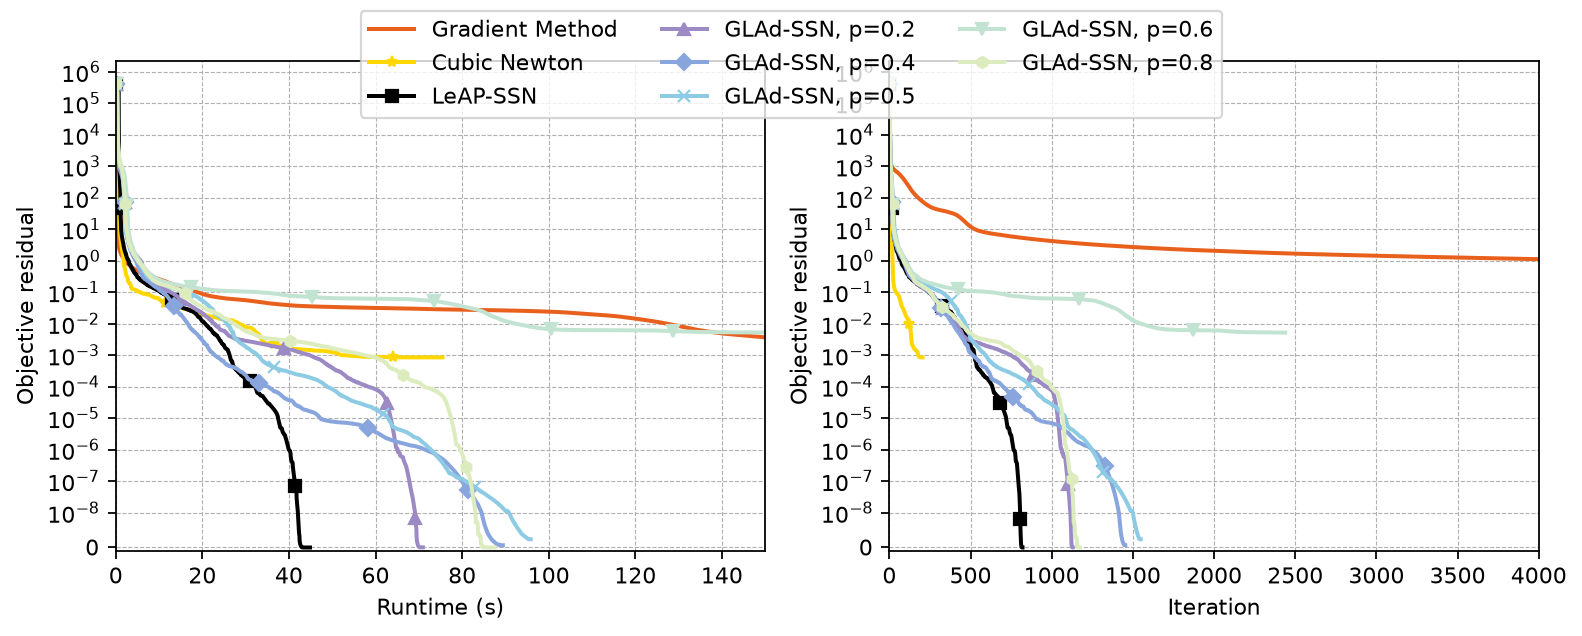

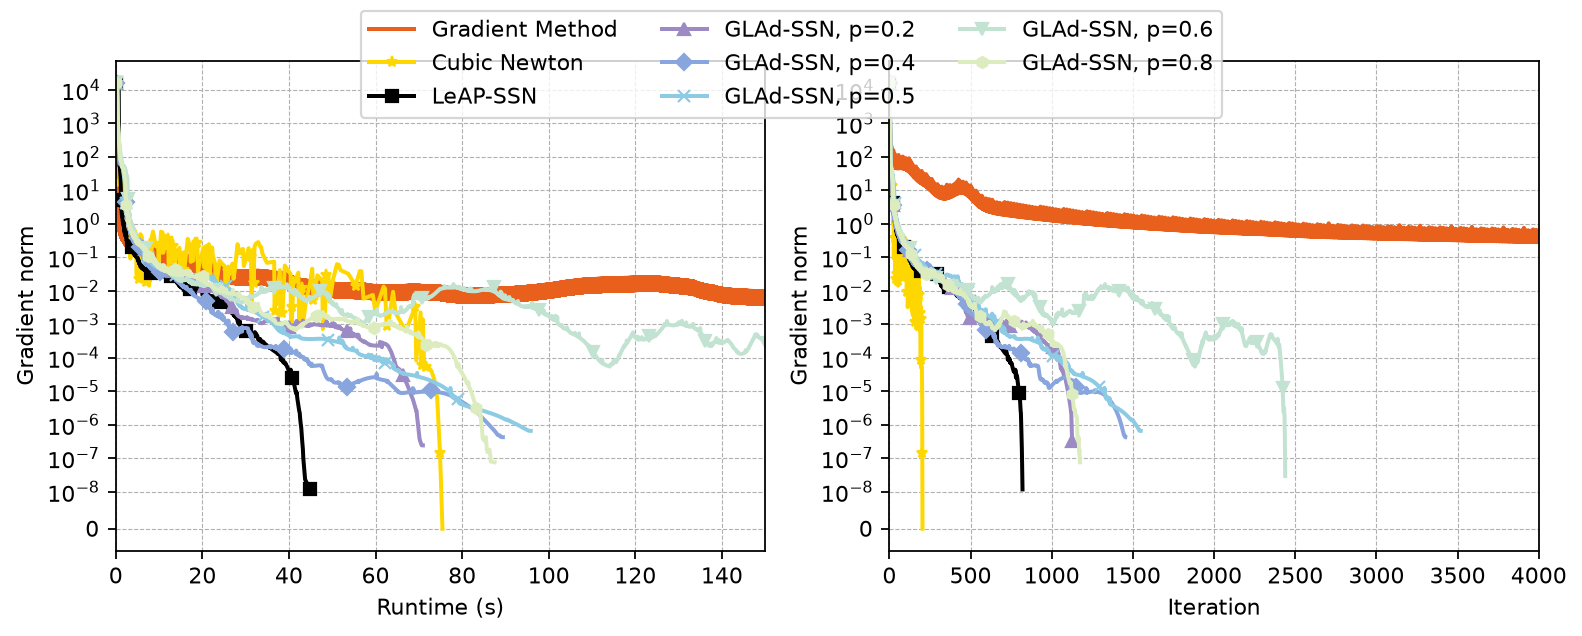

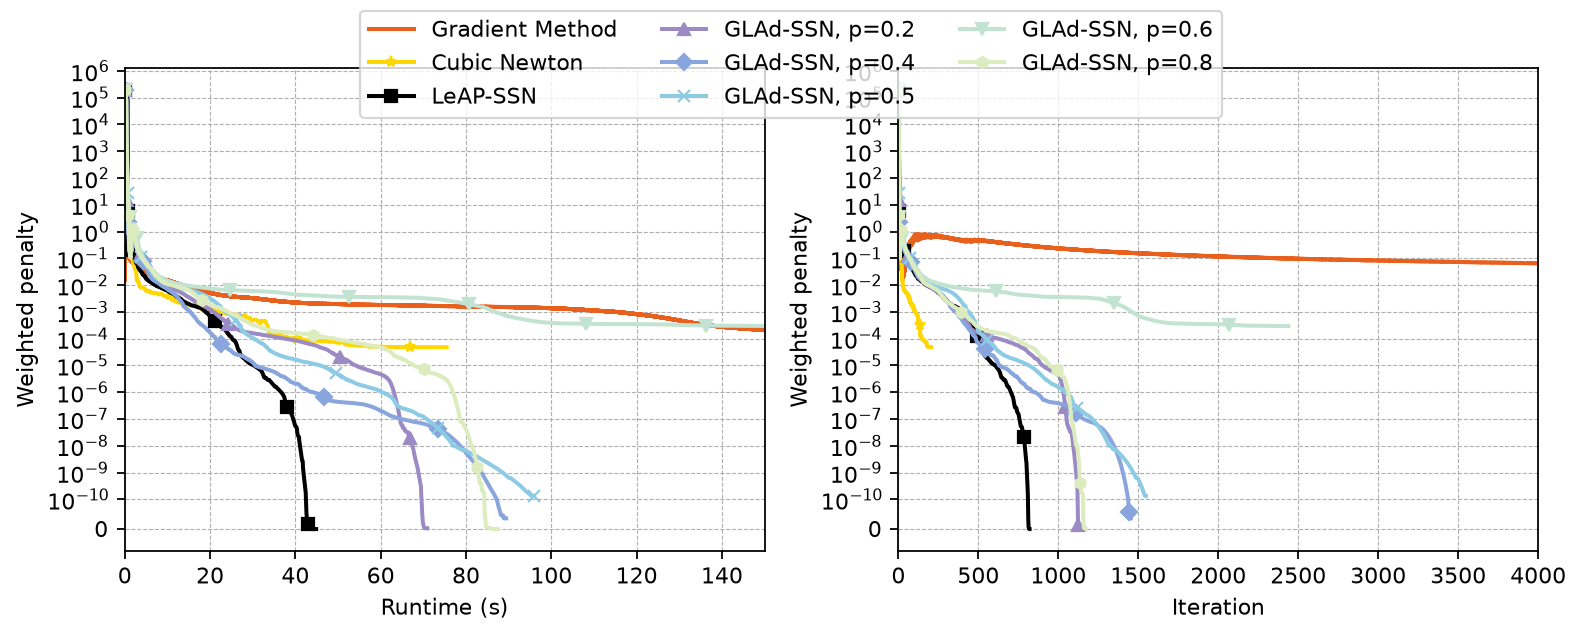

In [6]:
objective_reference = min(np.min(histories[selected_seed][name]["func"])
                          for name in representative_options["func"]["methods"])
for measure, suffix, ylabel in [("func", "objective", "Objective residual"),
                                ("grad_norm", "gradient", "Gradient norm"),
                                ("penalty", "penalty", "Weighted penalty")]:
    options = representative_options[measure]
    reference = float(objective_reference) if measure == "func" else 0.0
    fig = two_panel(histories[selected_seed], options, (measure, measure), ylabel, reference)
    retain_figure("representative_" + suffix, fig,
                  dict(seed=selected_seed, selection_role=selection_record["selected_seed_role"],
                       measure=measure, options=options, objective_reference=reference,
                       styles=plot_styles(options["methods"])))

## All-seed arithmetic means

Every seed has equal weight, including unsuccessful runs. After a run ends,
its terminal value is held. Runtime means use the most recently recorded value
on the shared timestamp grid; there is no interpolation or logarithmic averaging.
The gradient display ends when all seeds are currently below the recorded target,
or trims the final plateau with the saved relative tolerance. These are display
cutoffs, not altered solver stopping rules. Penalty rebounds and zeros are retained.

The first three plots reproduce the saved eight-method export. The fourth adds
PALM and the GN variants, reproducing the revision's Figures 7 and 9.
Rebuilding these means can take several minutes. Each figure is rendered to
compact PDF/PNG bytes and its large working arrays are released before moving on;
the exported curves still retain every recorded point used by the original plotter.

Preparing mean_objective over all 20 seeds...


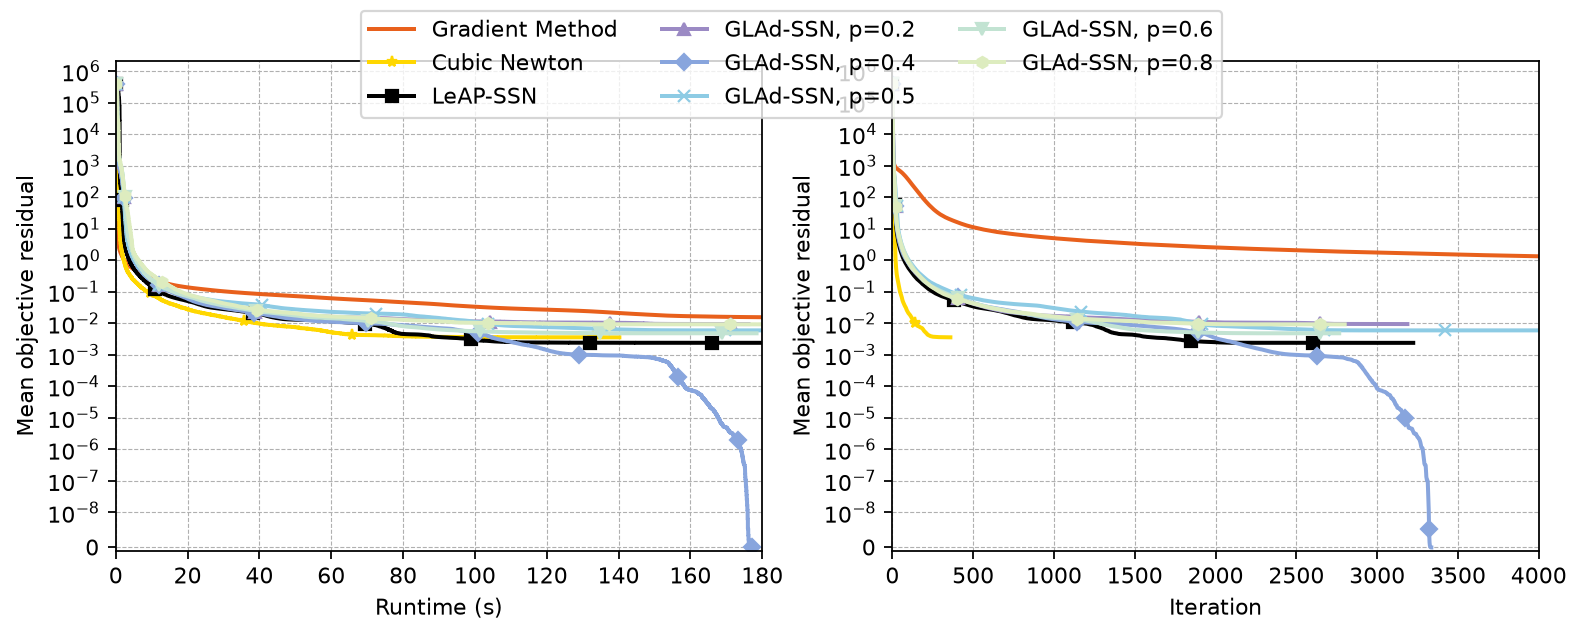

Preparing mean_gradient over all 20 seeds...


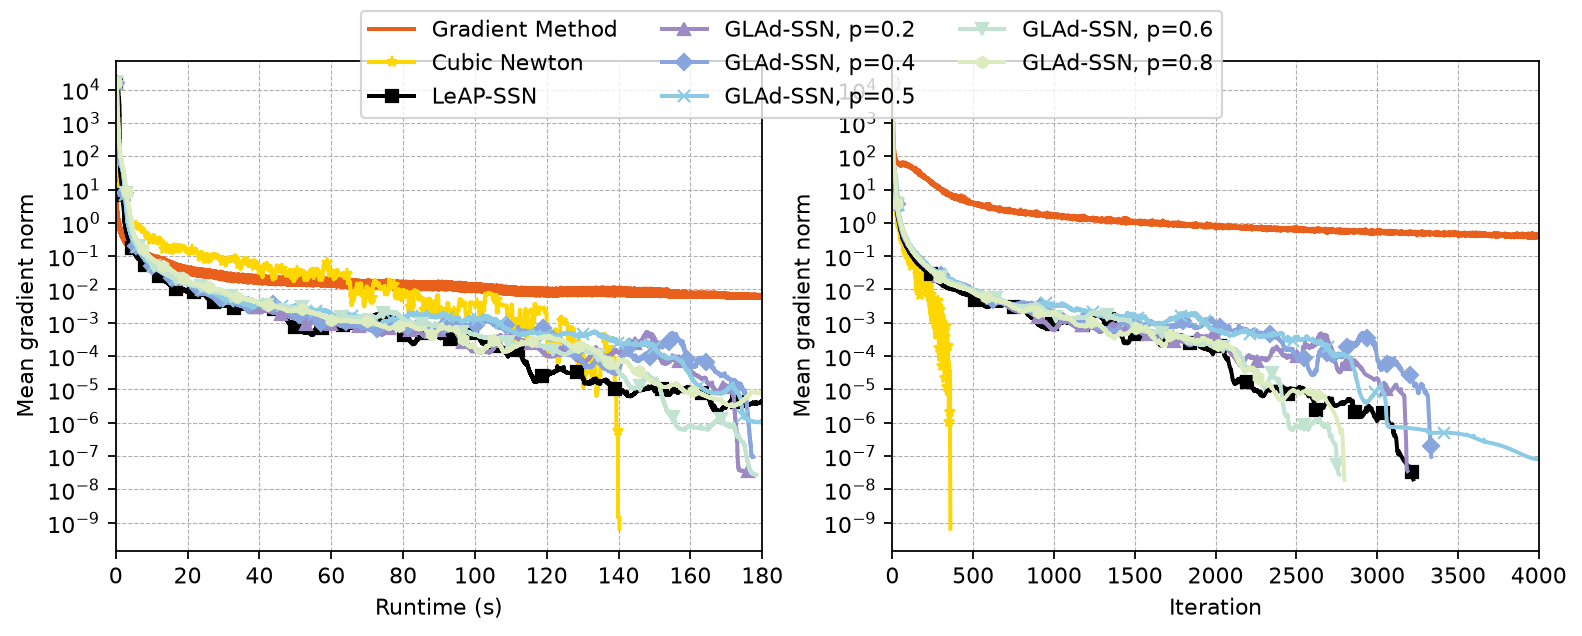

Preparing mean_penalty over all 20 seeds...


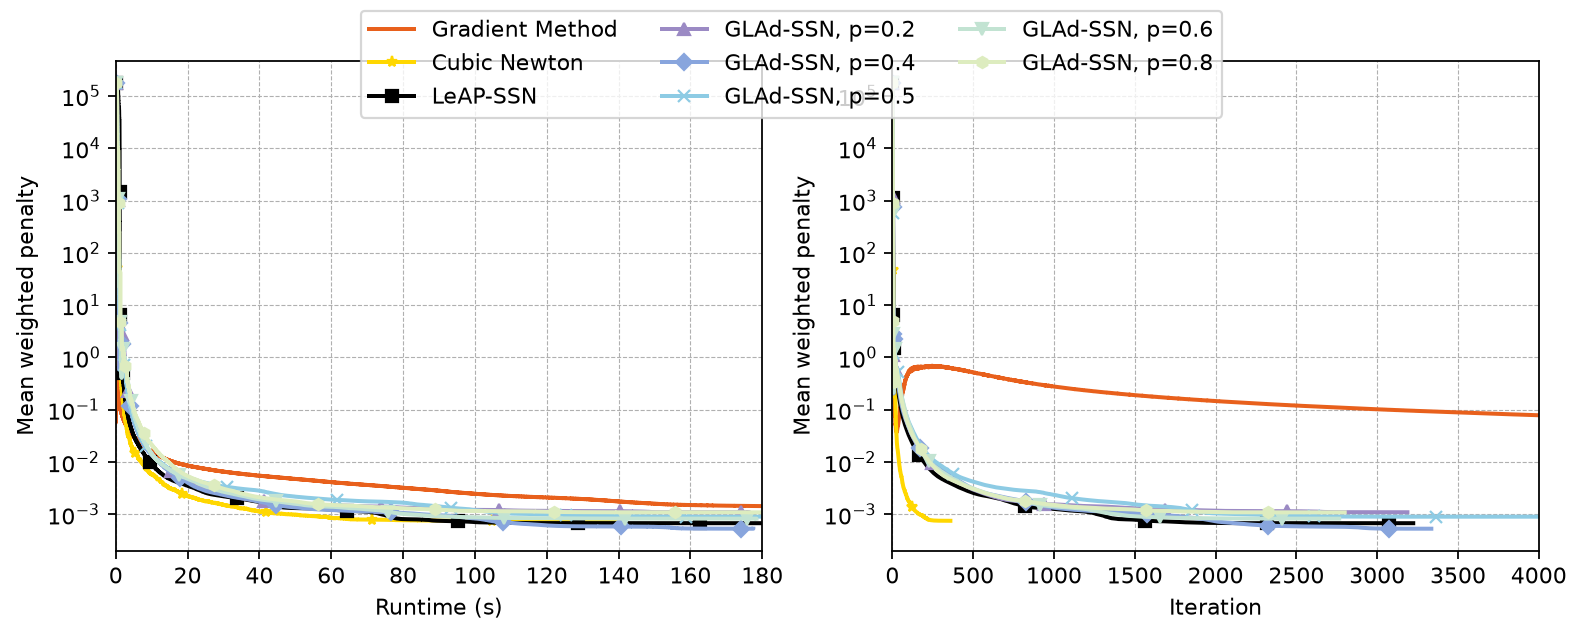

Preparing mean_gradient_GN_all over all 20 seeds...


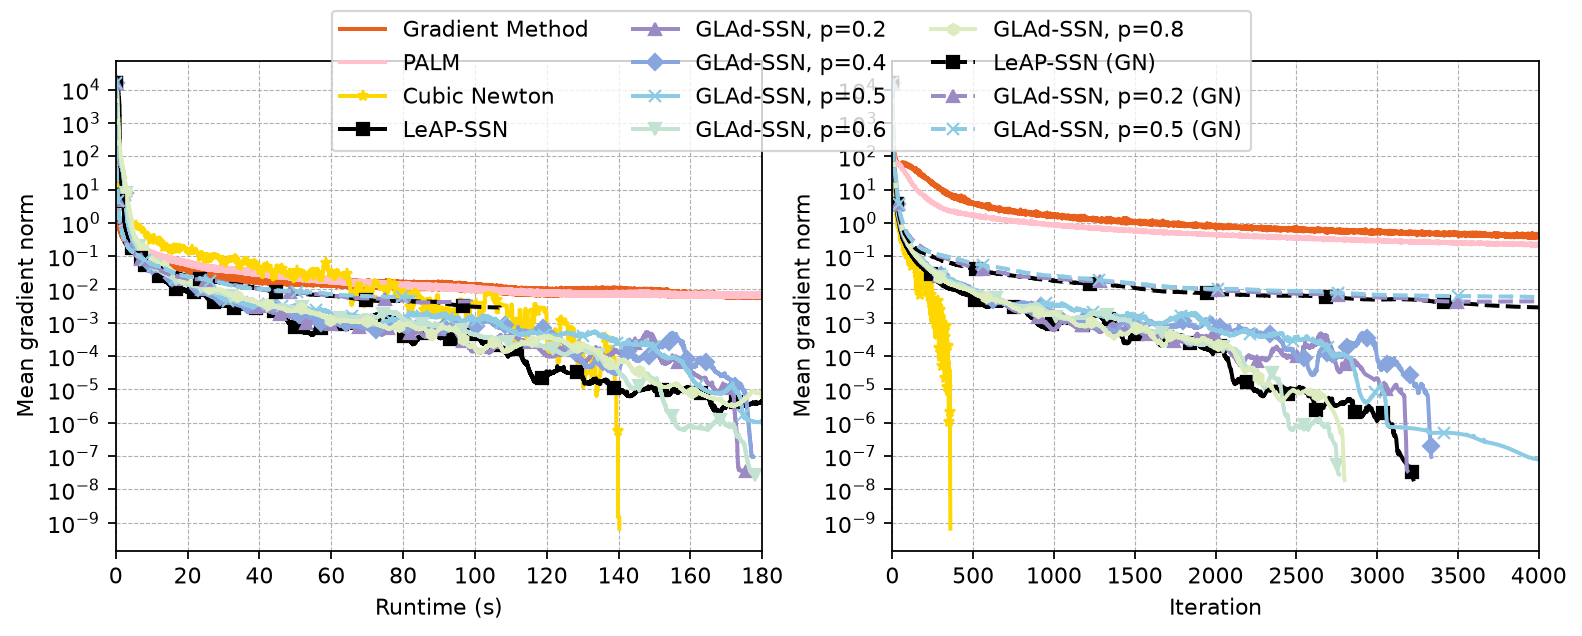

7809

In [7]:
def render_mean(measure, options, name, ylabel):
    print(f"Preparing {name} over all {len(seeds)} seeds...", flush=True)
    validate_options(options)
    target = mean_gradient_target if measure == "grad_norm" else None
    flat_tail = mean_gradient_flat_tail_rtol if measure == "grad_norm" else None
    prepared, summary = prepare_mean_histories(histories, options["methods"], measure=measure,
                                              target=target, flat_tail_rtol=flat_tail)
    reference = (min(float(np.min(v)) for panel in summary.values() for v in panel["means"].values())
                 if measure == "func" else 0.0)
    resolved = deepcopy(options)
    for axis, key in [("runtime", "max_time"), ("iteration", "max_iter")]:
        if resolved[key] is None:
            resolved[key] = max(1e-12, max(e["x"] for e in summary[axis]["endpoints"].values()))
    fig = two_panel(prepared, resolved, ("runtime", "iteration"), ylabel, reference, mean=True)
    compact_summary = {axis: dict(grid_size=len(panel["grid"]), grid_start=float(panel["grid"][0]),
                                  grid_end=float(panel["grid"][-1]), endpoints=panel["endpoints"])
                       for axis, panel in summary.items()}
    retain_figure(name, fig, dict(seeds=seeds, measure=measure, options=resolved,
                                 requested_options=options, objective_reference=reference,
                                 target=target, flat_tail_rtol=flat_tail, summaries=compact_summary,
                                 styles=plot_styles(options["methods"]),
                                 convention=saved["arithmetic_mean"]["convention"]))

for measure, suffix, ylabel in [("func", "objective", "Mean objective residual"),
                                ("grad_norm", "gradient", "Mean gradient norm"),
                                ("penalty", "penalty", "Mean weighted penalty")]:
    render_mean(measure, mean_options[measure], "mean_" + suffix, ylabel)
    gc.collect()
render_mean("grad_norm", mean_all_options, "mean_gradient_GN_all", "Mean gradient norm")
gc.collect()

## PALM comparison (revision Figure 10)

Both plots below use `PALM_SEED`, or follow `SELECTED_SEED` when it is `None`.
Rerun **Choose seeds and plot settings** and this cell after changing the seed.
The gradient comparison and weighted penalty are shown together so their
trajectories can be assessed consistently. The original export called these
files `figure8_gradient.pdf` and `figure8_penalty.pdf`.

PALM comparison: seed 107 (saved representative).


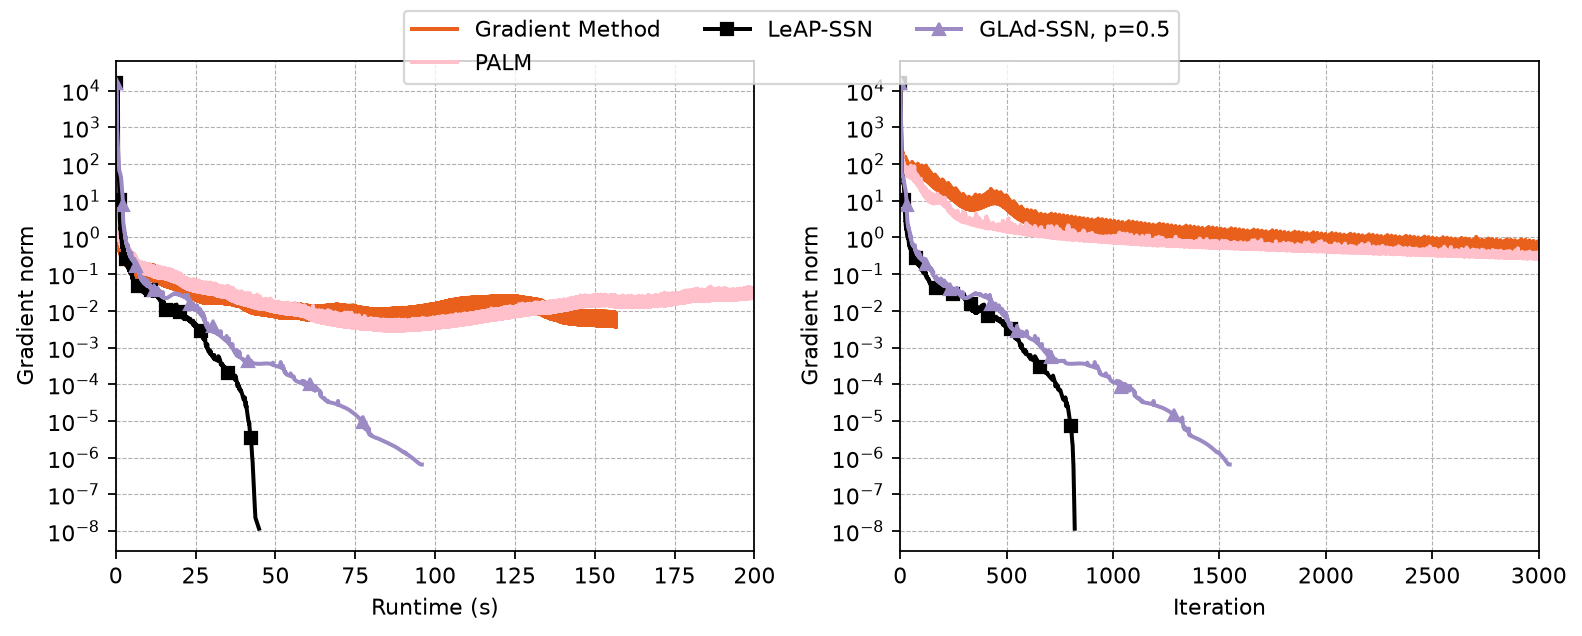

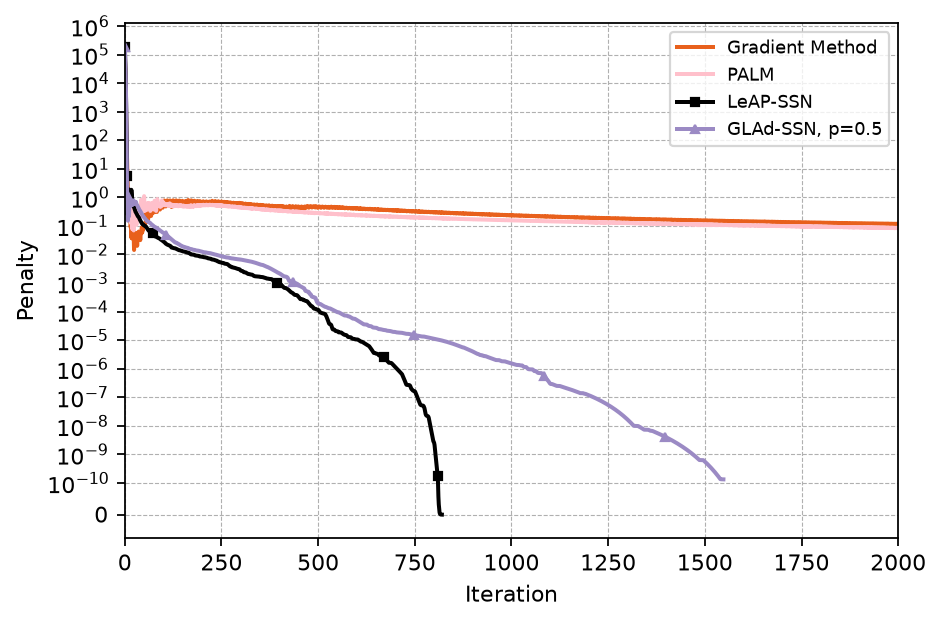

,seed,LeAP iterations,LeAP seconds,LeAP final gradient,LeAP exit,GLAd iterations,GLAd seconds,GLAd final gradient,GLAd exit,GLAd/LeAP seconds,GLAd/LeAP iterations,both reached,close
14,107,813,42.8444,0.0000,"numerical_stagnation, 820 iters",1518,92.8027,0.0000,"numerical_stagnation, 1548 iters",2.1660,1.8672,True,False


In [8]:
def render_penalty(seed, options, name, role, palm=False):
    validate_options(options)
    names = options["methods"]
    styles = plot_styles(names, palm=palm)
    fig = plot_penalty_iterations(
        [histories[seed][method] for method in names], names,
        colors=[s["color"] for s in styles], linewidths=[LINE_WIDTH] * len(names),
        linestyles=[s["linestyle"] for s in styles], marker_cycle=[s["marker"] for s in styles],
        markevery=MARKER_SPACING, max_iter=options["max_iter"], ylim=options["ylim"],
        zero_scale=options["zero_scale"], figsize=options["figsize"], legend_loc=options["legend_loc"],
    )
    retain_figure(name, fig, dict(seed=seed, selection_role=role, measure="penalty",
                                 options=options, styles=styles))

print(f"PALM comparison: seed {palm_seed} ({selection_record['palm_seed_role']}).")
fig = two_panel(histories[palm_seed], palm_gradient_options, ("grad_norm", "grad_norm"),
                "Gradient norm", palm=True)
retain_figure("palm_gradient", fig,
              dict(seed=palm_seed, selection_role=selection_record["palm_seed_role"],
                   measure="grad_norm", options=palm_gradient_options,
                   styles=plot_styles(palm_gradient_options["methods"], palm=True)))
render_penalty(palm_seed, palm_penalty_options, "palm_penalty", selection_record["palm_seed_role"], palm=True)
display(seed_comparison.loc[seed_comparison.seed == palm_seed].drop(columns=["distance from equal time"])
        .style.format(precision=4, na_rep="not reached"))

## Figure 3: weighted nonnegativity penalty

This uses the same selected seed as the representative objective and gradient.
The plotted quantity is beta/2 times the squared negative-part norms, exactly
as stored in `penalty`. All recorded values, including zeros and rebounds, remain.

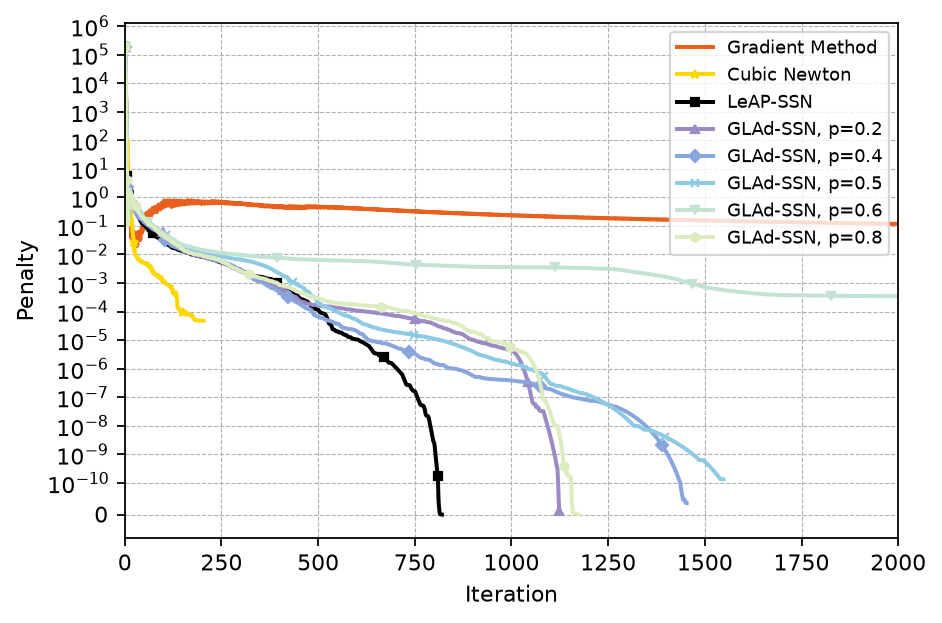

In [9]:
render_penalty(selected_seed, figure3_options, "figure3_penalty", selection_record["selected_seed_role"])

## Export the displayed figures

Set `SAVE_FIGURES=True` and run this cell after the desired plotting cells.
It writes only the currently rendered figures to a **new**
`parallel_results/replot_<timestamp>/` directory, with PDFs, optional PNG previews,
the all-seed comparison CSV and a JSON manifest recording seeds, settings,
selection roles, source snapshot/hash and package versions. Original exports
are never overwritten. The 207 MiB raw snapshot is referenced, not duplicated.

Changing seed/settings clears the figure collection to prevent exporting stale
plots. Rerun all plotting cells for a complete export, or just the PALM cell
for a deliberate two-figure export. The manifest lists what was actually saved.

In [10]:
SAVE_FIGURES = False
SAVE_PNG = True

if SAVE_FIGURES:
    if not figures:
        raise ValueError("Run the desired plotting cells before exporting.")
    output_dir = MF_DIR / "parallel_results" / ("replot_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    output_dir.mkdir(parents=True, exist_ok=False)
    for name, artifact in figures.items():
        (output_dir / f"{name}.pdf").write_bytes(artifact["pdf"])
        if SAVE_PNG:
            (output_dir / f"{name}.png").write_bytes(artifact["png"])
    seed_comparison.to_csv(output_dir / "seed_comparison.csv", index=False)
    manifest = dict(
        format="saved-parallel-nmf-replot", version=1,
        source=str(source_file), source_sha256=source_sha256,
        seeds=seeds, configuration=configuration, selection=selection_record,
        comparison=comparison_record, figures=figure_records,
        packages=dict(python=platform.python_version(), numpy=np.__version__,
                      pandas=pd.__version__, matplotlib=matplotlib.__version__),
        recorded_environment=recorded_metadata,
    )
    (output_dir / "replot_manifest.json").write_text(json.dumps(manifest, indent=2, allow_nan=False), encoding="utf-8")
    print(f"Saved {len(figures)} figures and their provenance to {output_dir}")
else:
    print("Export disabled. Set SAVE_FIGURES=True in this cell to save the displayed figures.")

Export disabled. Set SAVE_FIGURES=True in this cell to save the displayed figures.


## Validation scope

This is a reader of the recorded full run, not a new full reproduction from
random data. Fresh-kernel validation loads the 20-by-12 snapshot, renders all
10 graphics, checks the default figures against the saved PDF drawing streams,
and checks an explicit PALM seed change. No training or optimization is run.
The saved snapshot and original notebook remain unchanged. The comparison
table uses actual first-crossing times and indices and retains missing targets.